In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os
print(os.getcwd())

C:\Users\DELL\OneDrive\Desktop\predictive-maintenance-flask\notebooks


In [3]:
d=pd.read_csv("../data/ai4i2020.csv")
d

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [4]:
d.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
d.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [6]:
d.shape

(10000, 14)

In [7]:
d.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [8]:
d.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [9]:
d.isnull().sum() #no null values in the dataset

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [10]:
d.duplicated().sum() # no duplicates

np.int64(0)

In [11]:
d["Machine failure"].value_counts()
d["Machine failure"].value_counts(normalize=True)

Machine failure
0    0.9661
1    0.0339
Name: proportion, dtype: float64

In [12]:
d["any_mode"] = d[["TWF","HDF","PWF","OSF","RNF"]].sum(axis=1) > 0
pd.crosstab(d["any_mode"], d["Machine failure"])

Machine failure,0,1
any_mode,,
False,9643,9
True,18,330


In [13]:
d = d.drop(columns=["UDI","Product ID","TWF","HDF","PWF","OSF","RNF","any_mode"])
d.columns #udi and prodid is not effecting or contibuting to our model so no need of that then the other 5 failure subtypes will allow data leakage so that also need to be removed

Index(['Type', 'Air temperature [K]', 'Process temperature [K]',
       'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]',
       'Machine failure'],
      dtype='str')

In [14]:
num = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

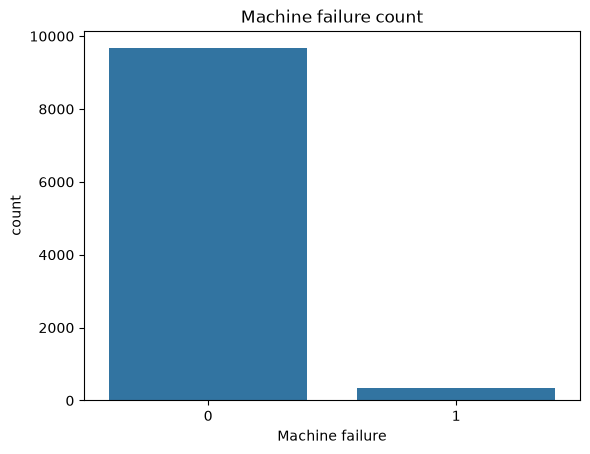

In [15]:
sns.countplot(x="Machine failure", data=d)
plt.title("Machine failure count")
plt.show()

#failure vs no failure counts are having severe imbalace

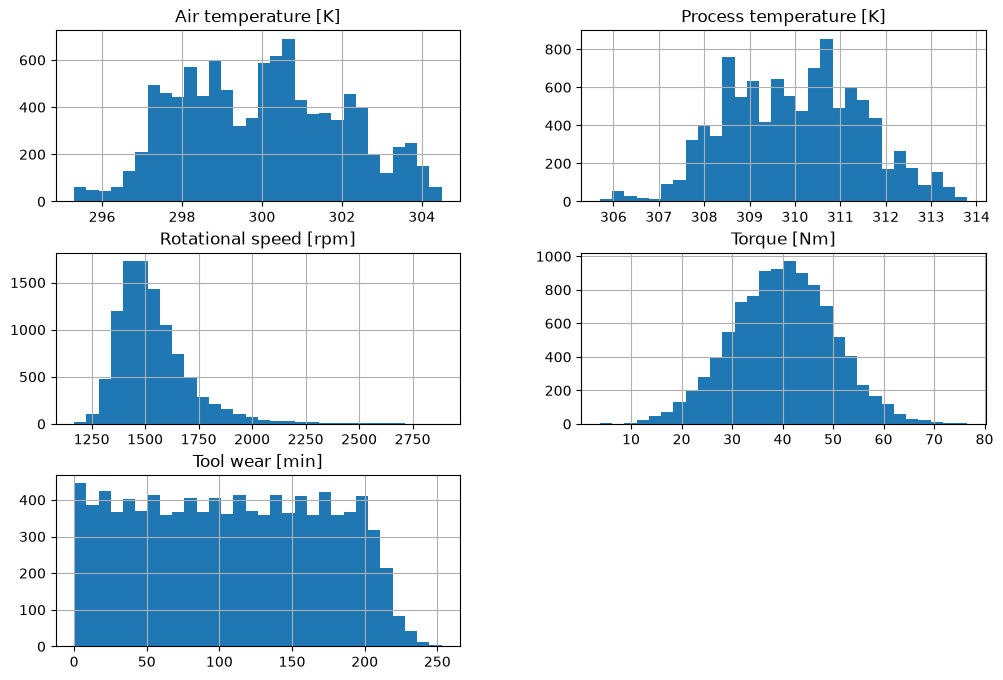

In [16]:
#distribution of each feature

d[num].hist(bins=30, figsize=(12, 8))
plt.show()

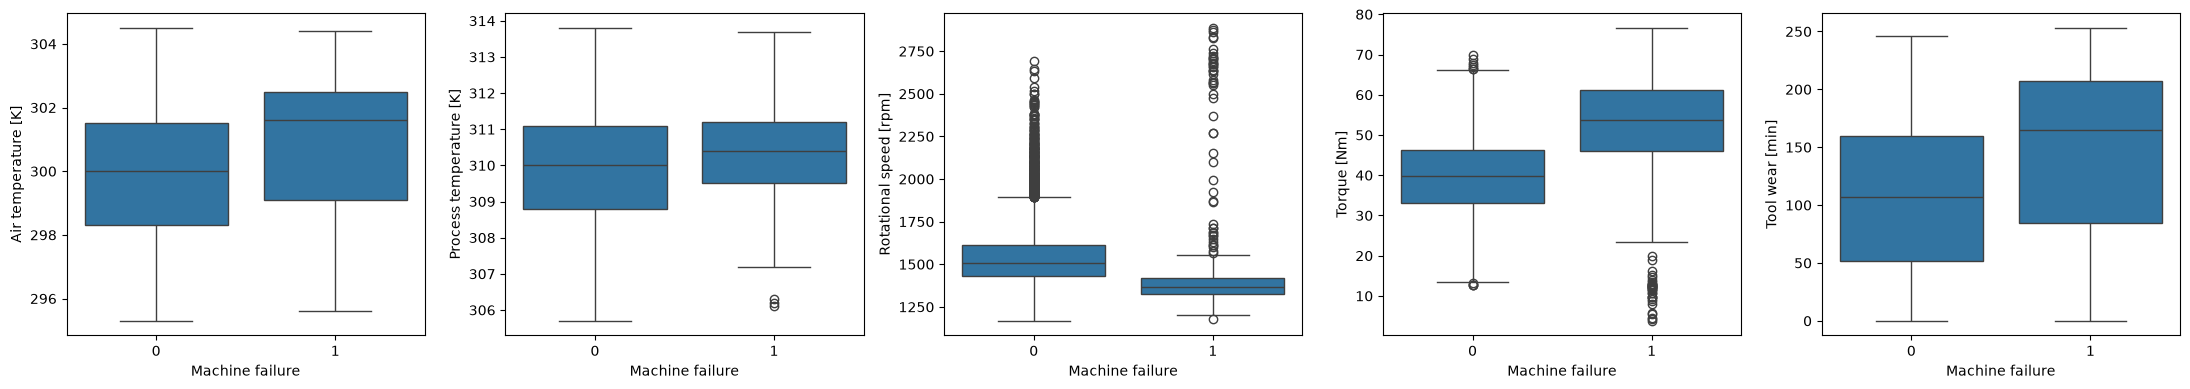

In [17]:
#sensors split by failure box plots

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, c in zip(axes, num):
    sns.boxplot(x="Machine failure", y=c, data=d, ax=ax)
plt.tight_layout()
plt.show()

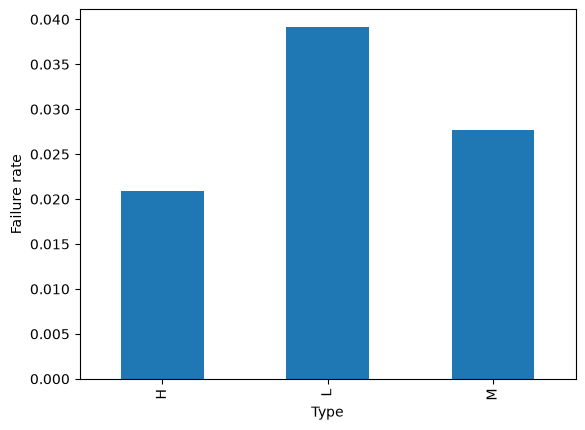

In [18]:
#failure by product type

d.groupby("Type")["Machine failure"].mean().plot(kind="bar")
plt.ylabel("Failure rate")
plt.show()

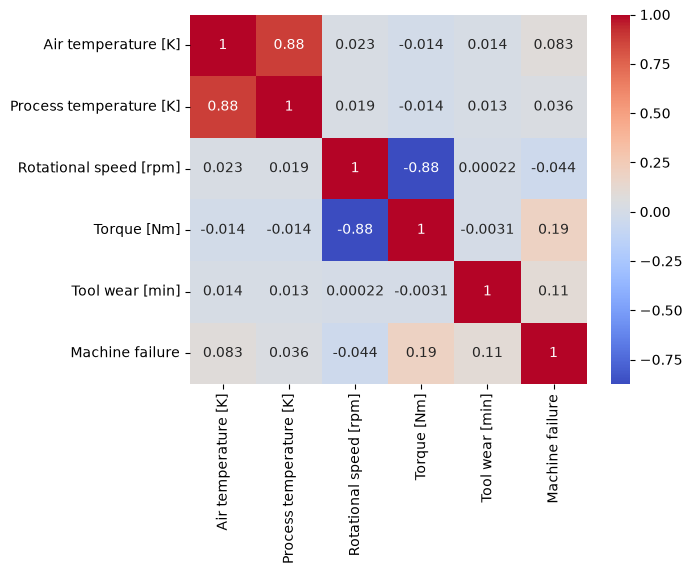

In [19]:
#corre heatmap

sns.heatmap(d[num + ["Machine failure"]].corr(), annot=True, cmap="coolwarm")
plt.show()

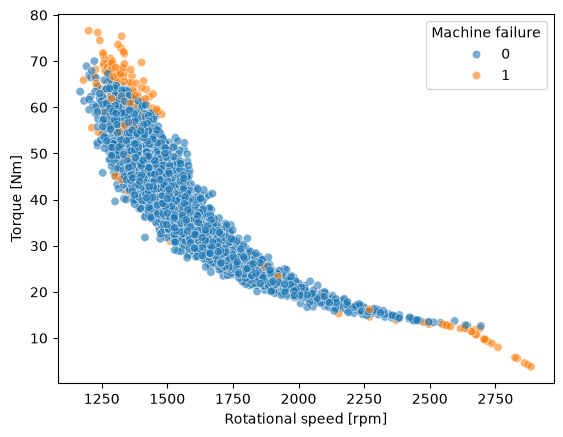

In [20]:
#torque vs rotational speed

sns.scatterplot(x="Rotational speed [rpm]", y="Torque [Nm]", hue="Machine failure", data=d, alpha=0.6)
plt.show()

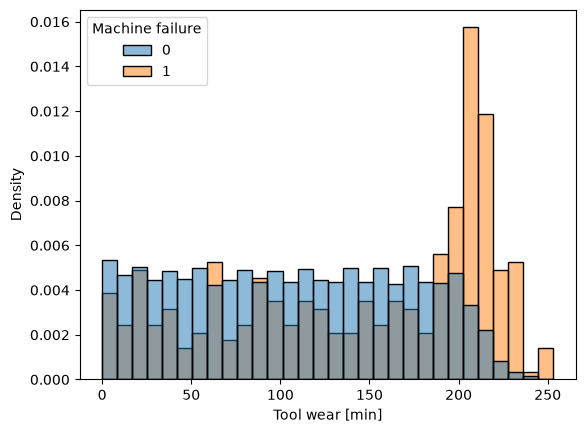

In [21]:
#toolwear vs failure

sns.histplot(data=d, x="Tool wear [min]", hue="Machine failure", bins=30, stat="density", common_norm=False)
plt.show()

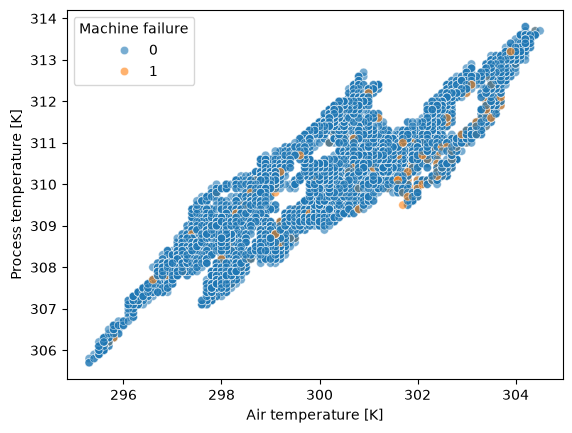

In [22]:
#air vs process temp

sns.scatterplot(x="Air temperature [K]", y="Process temperature [K]", hue="Machine failure", data=d, alpha=0.6)
plt.show()

In [23]:
d["temp_diff"] = d["Process temperature [K]"] - d["Air temperature [K]"] #gap btw process and air temp, failed machines have smaller gap
d["power_W"] = d["Torque [Nm]"] * d["Rotational speed [rpm]"] * 2 * np.pi / 60 #power=torque*angular speed so multiplying will give watts
d["torque_wear"] = d["Torque [Nm]"] * d["Tool wear [min]"] #high load on worn tool so there is a chance for overtrain

In [24]:
#average of each by failure

d.groupby("Machine failure")[["temp_diff", "power_W", "torque_wear"]].mean()

,temp_diff,power_W,torque_wear
Machine failure,,,
0,10.021571,6244.547534,4213.842708
1,9.403835,7282.819485,7187.938348


In [25]:
from sklearn.model_selection import train_test_split

In [26]:
#train test split
X = d.drop(columns="Machine failure")
y = d["Machine failure"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
#stratify keeps the same 3.4% failure rate in both set

In [27]:
print(y_train.mean(), y_test.mean())

0.033875 0.034


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = X.drop(columns="Type").columns.tolist()
prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(), ["Type"])
])

#we split before preprocessing and the scaler is fitted on the training data only

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

In [30]:
#train and tuning models
models = {
    "Logistic Regression": (LogisticRegression(class_weight="balanced", max_iter=1000),
                            {"model__C": [0.1, 1, 10]}),
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=42),
                      {"model__max_depth": [3, 5, 10], "model__min_samples_leaf": [1, 5, 20]}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
                      {"model__n_estimators": [100, 200], "model__max_depth": [5, 10, None],
                       "model__min_samples_leaf": [1, 5]}),
    "ANN": (MLPClassifier(max_iter=500, random_state=42),
            {"model__hidden_layer_sizes": [(32,), (64, 32)], "model__alpha": [0.0001, 0.001]}),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best = {}
for name, (m, grid) in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="average_precision", n_jobs=-1)
    gs.fit(X_train, y_train)
    best[name] = gs.best_estimator_
    print(name, gs.best_params_, round(gs.best_score_, 3))

Logistic Regression {'model__C': 0.1} 0.486
Decision Tree {'model__max_depth': 5, 'model__min_samples_leaf': 5} 0.83
Random Forest {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200} 0.888
ANN {'model__alpha': 0.001, 'model__hidden_layer_sizes': (64, 32)} 0.769


In [31]:
#evaluate on test data
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,recall_score, f1_score, roc_auc_score, average_precision_score)

rows = []
for name, est in best.items():
    proba = est.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    print(name)
    print(confusion_matrix(y_test, pred))
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)
results

Logistic Regression
[[1639  293]
 [   8   60]]
Decision Tree
[[1834   98]
 [   5   63]]
Random Forest
[[1928    4]
 [  12   56]]
ANN
[[1915   17]
 [  18   50]]


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,0.850,0.170,0.882,0.285,0.931,0.440
Decision Tree,0.948,0.391,0.926,0.550,0.956,0.876
Random Forest,0.992,0.933,0.824,0.875,0.970,0.862
ANN,0.982,0.746,0.735,0.741,0.980,0.821


In [32]:
#rf is best bcs it has good score in cross validation and best f1 score, also second highest roc-auc
#ann has highest roc-auc but f1 and pr-auc is low

In [33]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

rf = best["Random Forest"]
oof = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
p, r, t = precision_recall_curve(y_train, oof)

ok = np.where(r[:-1] >= 0.90)[0]   # thresholds that still catch at least 90% of failures
thr = t[ok[-1]]                    # the highest such threshold (fewest false alarms)
print("threshold:", round(thr, 3), "precision:", round(p[ok[-1]], 3), "recall:", round(r[ok[-1]], 3))

threshold: 0.15 precision: 0.446 recall: 0.9


In [34]:
proba = rf.predict_proba(X_test)[:, 1]
pred = (proba >= thr).astype(int)
print(confusion_matrix(y_test, pred))
print("Precision:", precision_score(y_test, pred), "Recall:", recall_score(y_test, pred))

[[1856   76]
 [   7   61]]
Precision: 0.44525547445255476 Recall: 0.8970588235294118


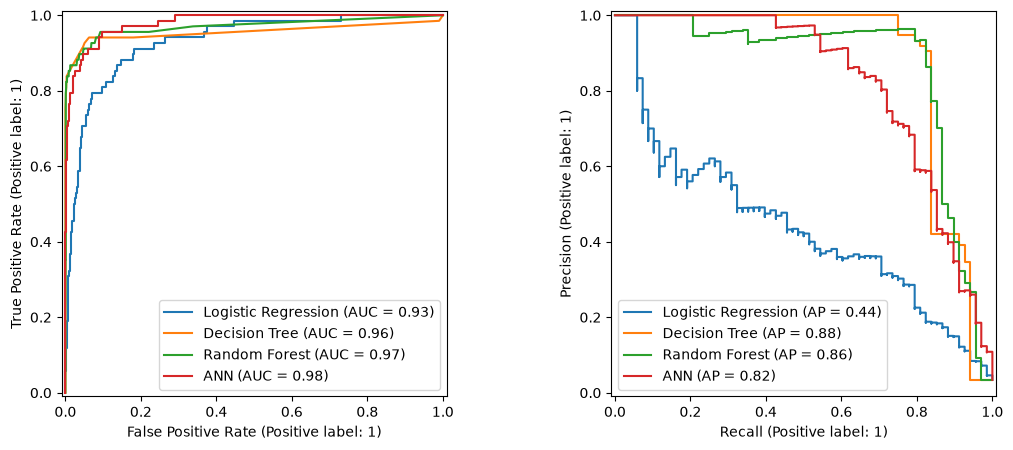

In [35]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, est in best.items():
    RocCurveDisplay.from_estimator(est, X_test, y_test, ax=ax[0], name=name)
    PrecisionRecallDisplay.from_estimator(est, X_test, y_test, ax=ax[1], name=name)
plt.show()

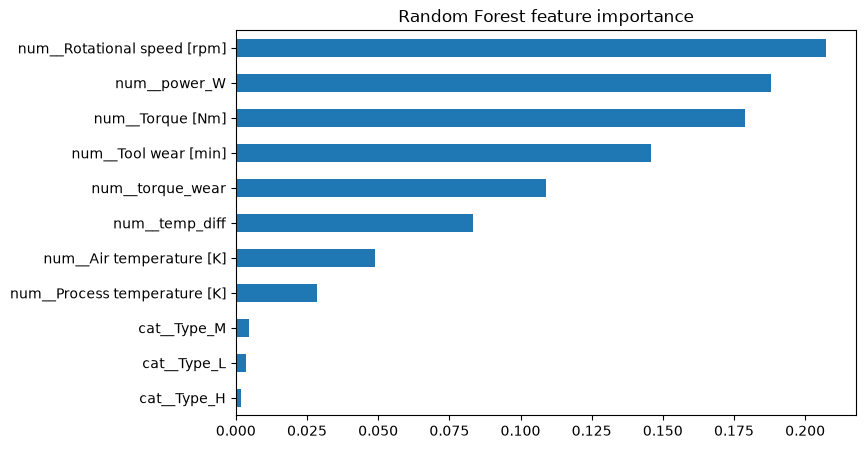

In [36]:
names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values()
imp.plot(kind="barh", figsize=(8, 5))
plt.title("Random Forest feature importance")
plt.show()

In [37]:
thr = 0.15

In [38]:
import joblib, json, os
os.makedirs("../models", exist_ok=True)

joblib.dump(rf, "../models/rf_pipeline.joblib")

proba = rf.predict_proba(X_test)[:, 1]
pred = (proba >= thr).astype(int)
info = {
    "threshold": float(thr),
    "feature_columns": X.columns.tolist(),
    "model_comparison": results.reset_index().to_dict(orient="records"),
    "final_model_metrics": {
        "precision": float(precision_score(y_test, pred)),
        "recall": float(recall_score(y_test, pred)),
        "f1": float(f1_score(y_test, pred)),
        "roc_auc": float(roc_auc_score(y_test, proba)),
        "pr_auc": float(average_precision_score(y_test, proba)),
        "confusion_matrix": confusion_matrix(y_test, pred).tolist(),
    },
    "dataset_stats": {"rows": int(len(d)), "failure_rate": float(y.mean())},
}
with open("../models/model_info.json", "w") as f:
    json.dump(info, f, indent=2)

In [39]:
thr = 0.15
proba = rf.predict_proba(X_test)[:, 1]
pred = (proba >= thr).astype(int)
print(confusion_matrix(y_test, pred))
print("Precision:", precision_score(y_test, pred), "Recall:", recall_score(y_test, pred))

[[1856   76]
 [   7   61]]
Precision: 0.44525547445255476 Recall: 0.8970588235294118


In [40]:
cols = ["Type", "Air temperature [K]", "Process temperature [K]",
        "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
sample = pd.concat([X_test[y_test == 1][cols].head(10),
                    X_test[y_test == 0][cols].head(20)])
sample.to_csv("../data/sample_batch.csv", index=False)